In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from datetime import datetime


class ImagePacketDecoder:
    """
    RAW16 UART 图像包解析器（支持行扩展 + ADC）

    UART 包格式（BE）:
        FF FF +
        H * (W + 2) * u16   (图像 + 行扩展) +
        1 * u16            (ADC + flag)

    ADC 定义:
        bit15      : flag (HEAD / shutter)
        bit11..0   : ADC raw value (0~4095)
    """

    def __init__(self, width, height, calib_file=None):
        self.width = width
        self.height = height

        self.line_words = self.width + 2
        self.total_words = self.height * self.line_words + 1
        self.packet_size = 2 + self.total_words * 2

        self.calib = None
        if calib_file is not None:
            self._load_calibration(calib_file)

    def _load_calibration(self, calib_file):
        calib = np.load(calib_file)
        if calib.shape != (self.height, self.width):
            raise ValueError("Calibration shape mismatch")
        self.calib = calib.astype(np.int32)

    @staticmethod
    def gray_to_binary(img):
        return img

    def feed_packet(self, packet):
        if len(packet) != self.packet_size:
            return None
        if packet[0] != 0xFF or packet[1] != 0xFF:
            return None

        buf8 = np.frombuffer(packet[2:], dtype=np.uint8)

        raw16 = (buf8[0::2].astype(np.uint16) << 8) | \
                buf8[1::2].astype(np.uint16)

        adc_raw = int(raw16[-1])
        raw16_main = raw16[:-1]

        raw16_all = raw16_main.reshape(
            (self.height, self.line_words)
        )

        raw_img = raw16_all[:, :self.width]
        raw_ext = raw16_all[:, self.width:]

        img = self.gray_to_binary(raw_img).astype(np.int32)
        if self.calib is not None:
            img -= self.calib
            img = np.clip(img, 0, 65535)

        img_all = np.concatenate(
            [img.astype(np.uint16), raw_ext.astype(np.uint16)],
            axis=1
        )

        return img_all, adc_raw


def run_uart_capture(port, baud, width, height, calib_file=None):
    folder = datetime.now().strftime("capture_%Y%m%d_%H%M%S")
    os.makedirs(folder, exist_ok=True)

    npy_path = os.path.join(folder, "frames.npy")

    frame_dtype = np.dtype([
        ("img", np.uint16, (height, width + 2)),
        ("adc", np.uint16),   # 仅保存 12bit ADC
    ])

    frames = []
    decoder = ImagePacketDecoder(width, height, calib_file)
    buf = bytearray()

    head_frame = None

    try:
        with serial.Serial(port, baud, timeout=0.01) as ser:
            print("Receiving frames (bit15 used only in HEAD)")

            while True:
                buf.extend(ser.read(4096))

                while True:
                    idx = buf.find(b'\xFF\xFF')
                    if idx < 0:
                        buf = buf[-1:]
                        break

                    if len(buf) - idx < decoder.packet_size:
                        buf = buf[idx:]
                        break

                    packet = buf[idx:idx + decoder.packet_size]
                    buf = buf[idx + decoder.packet_size:]

                    result = decoder.feed_packet(packet)
                    if result is None:
                        continue

                    img_all, adc_raw = result

                    adc_flag = (adc_raw & 0x8000) != 0
                    adc_value = adc_raw & 0x0FFF

                    # ===== HEAD 帧 =====
                    if adc_flag:
                        head_frame = np.zeros((), dtype=frame_dtype)
                        head_frame["img"] = img_all
                        head_frame["adc"] = adc_value

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")
                        plt.title(f"HEAD adc={adc_value}")
                        plt.show()
                        continue

                    # ===== TAIL 帧（强制去掉最高位）=====
                    if head_frame is not None:
                        tail_frame = np.zeros((), dtype=frame_dtype)
                        tail_frame["img"] = img_all
                        tail_frame["adc"] = adc_raw & 0x0FFF  # 显式清 bit15

                        frames.append(head_frame)
                        frames.append(tail_frame)

                        print(
                            f"Saved group #{len(frames)//2}, "
                            f"total frames={len(frames)}"
                        )

                        head_frame = None

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")
                        plt.title(f"TAIL adc={tail_frame['adc']}")
                        plt.show()

    except KeyboardInterrupt:
        print("Stopped by user")

    frames_np = np.array(frames, dtype=frame_dtype)
    np.save(npy_path, frames_np)
    print(f"Saved {len(frames)//2} groups to {npy_path}")


if __name__ == "__main__":
    run_uart_capture(
        port="COM31",
        baud=5_000_000,
        width=160,
        height=120,
        calib_file=None,
    )

Receiving frames (bit15 used only in HEAD)
Stopped by user
Saved 0 groups to capture_20260127_172325\frames.npy


: 

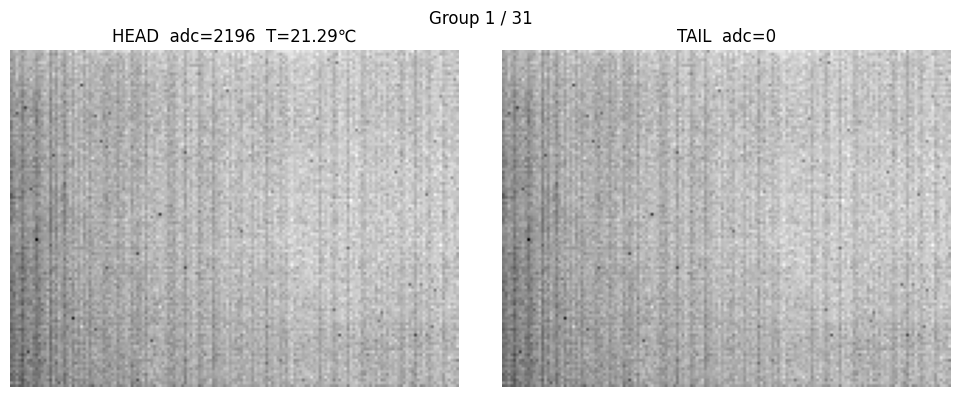

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# NTC 参数（固定）
# -----------------------------
RUP = 10_000.0      # 上拉电阻 10kΩ
R0  = 10_000.0      # 25℃ 标称电阻
T0  = 298.15        # 25℃ = 298.15K
B   = 3435.0        # B 值

def adc_to_rntc(adc):
    """
    ADC -> NTC 电阻（Ohm）
    """
    adc = float(adc)
    if adc <= 0 or adc >= 4095:
        return np.nan
    return RUP * adc / (4095.0 - adc)

def rntc_to_temp_c(r):
    """
    NTC 电阻 -> 温度（℃）
    """
    if r <= 0 or np.isnan(r):
        return np.nan
    inv_T = 1.0 / T0 + np.log(r / R0) / B
    return 1.0 / inv_T - 273.15

def adc_to_temp_c(adc):
    """
    ADC -> 温度（℃）
    """
    r = adc_to_rntc(adc)
    return rntc_to_temp_c(r)

def show_frame_group(npy_file, group_idx, width):
    """
    显示 frames.npy 中指定 index 的一组图像，并解码 ADC → 温度
    """

    frames = np.load(npy_file)

    if frames.dtype.fields is None:
        raise ValueError("frames.npy is not a structured array")

    total_groups = len(frames) // 2
    if group_idx < 0 or group_idx >= total_groups:
        raise IndexError(
            f"group_idx out of range (0 ~ {total_groups - 1})"
        )

    head = frames[group_idx * 2]
    tail = frames[group_idx * 2 + 1]

    img_head = head["img"][:, :width]
    img_tail = tail["img"][:, :width]

    # ===== ADC 解码 =====
    adc_head = int(head["adc"])
    adc_tail = int(tail["adc"])

    temp_head = adc_to_temp_c(adc_head)
    temp_tail = adc_to_temp_c(adc_tail)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(img_head, cmap="gray")
    axes[0].set_title(
        f"HEAD  adc={adc_head}  T={temp_head:.2f}℃"
        if not np.isnan(temp_head)
        else f"HEAD  adc={adc_head}"
    )

    axes[1].imshow(img_tail, cmap="gray")
    axes[1].set_title(
        f"TAIL  adc={adc_tail}  T={temp_tail:.2f}℃"
        if not np.isnan(temp_tail)
        else f"TAIL  adc={adc_tail}"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Group {group_idx} / {total_groups - 1}"
    )

    plt.tight_layout()
    plt.show()

show_frame_group(
    npy_file=r"capture_20260127_163913\frames.npy",
    group_idx=1,
    width=160
)

In [3]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import os
import numpy as np


def split_frames(npy_file, out_dir, height=120, width=160):
    frames = np.load(npy_file)

    if frames.dtype.fields is None:
        raise ValueError("frames.npy is not a structured array")

    if "img" not in frames.dtype.fields or "adc" not in frames.dtype.fields:
        raise ValueError("frames must contain 'img' and 'adc' fields")

    if len(frames) % 2 != 0:
        raise ValueError("frames count must be even (HEAD/TAIL pairs)")

    os.makedirs(out_dir, exist_ok=True)

    shutter_imgs = []
    black_imgs = []

    shutter_adc = []
    black_adc = []
    avg_adc = []

    total_groups = len(frames) // 2

    for i in range(total_groups):
        shutter = frames[2 * i]
        black   = frames[2 * i + 1]

        img_shutter = shutter["img"][:height, :width+2]
        img_black   = black["img"][:height, :width+2]

        adc_shutter = int(shutter["adc"])
        adc_black   = int(black["adc"])

        # --- 防御性检查（建议长期保留） ---
        if not (0 <= adc_shutter <= 4095):
            raise ValueError(
                f"Invalid shutter ADC at group {i}: {adc_shutter}"
            )
        if not (0 <= adc_black <= 4095):
            raise ValueError(
                f"Invalid black ADC at group {i}: {adc_black}"
            )

        shutter_imgs.append(img_shutter)
        black_imgs.append(img_black)

        shutter_adc.append(adc_shutter)
        black_adc.append(adc_black)

        avg_adc.append((adc_shutter + adc_black) / 2.0)

    # --- 转 numpy ---
    shutter_imgs = np.asarray(shutter_imgs, dtype=np.uint16)
    black_imgs   = np.asarray(black_imgs,   dtype=np.uint16)

    shutter_adc = np.asarray(shutter_adc, dtype=np.int32)
    black_adc   = np.asarray(black_adc,   dtype=np.int32)
    avg_adc     = np.asarray(avg_adc,     dtype=np.float32)

    # --- 保存 ---
    np.save(os.path.join(out_dir, "shutter_img.npy"), shutter_imgs)
    np.save(os.path.join(out_dir, "black_img.npy"),   black_imgs)

    np.save(os.path.join(out_dir, "shutter_adc.npy"), shutter_adc)
    np.save(os.path.join(out_dir, "black_adc.npy"),   black_adc)
    np.save(os.path.join(out_dir, "avg_adc.npy"),     avg_adc)

    print("Split finished:")
    print(f"  groups        : {total_groups}")
    print(f"  shutter img   : {shutter_imgs.shape}")
    print(f"  black img     : {black_imgs.shape}")
    print(f"  shutter adc   : {shutter_adc.shape}")
    print(f"  black adc     : {black_adc.shape}")
    print(f"  avg adc       : {avg_adc.shape}")


if __name__ == "__main__":
    npy_file = r"capture_20260127_163913\frames.npy"
    out_dir  = r"capture_20260127_163913"

    split_frames(npy_file, out_dir)


Split finished:
  groups        : 32
  shutter img   : (32, 120, 162)
  black img     : (32, 120, 162)
  shutter adc   : (32,)
  black adc     : (32,)
  avg adc       : (32,)


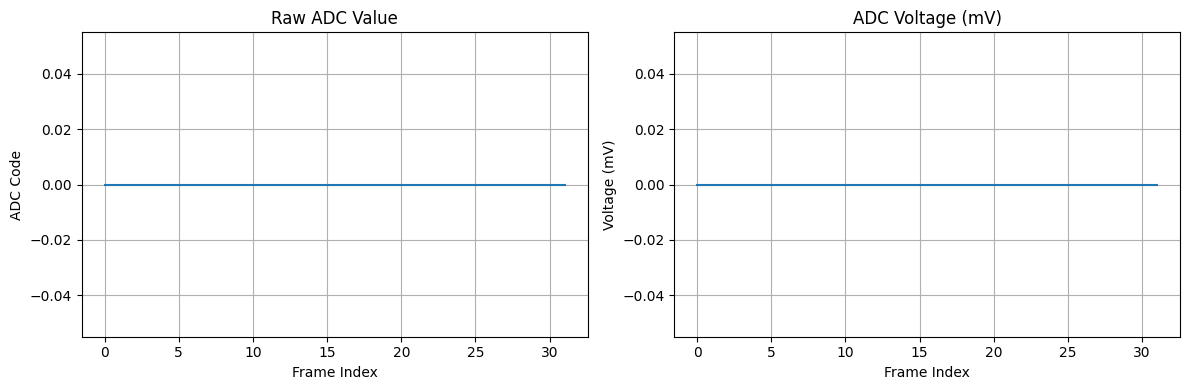

In [6]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 参数配置
# -----------------------------
ADC_FILE = r"capture_20260127_163913\black_adc.npy"
VREF = 3.3            # 参考电压 3.3V
ADC_BITS = 12         # ADC 位宽
ADC_MAX = (1 << ADC_BITS) - 1

# -----------------------------
# 加载 ADC 数据
# -----------------------------
adc = np.load(ADC_FILE)
x = np.arange(adc.size)

# -----------------------------
# ADC -> mV
# -----------------------------
adc_mv = adc.astype(np.float64) * VREF * 1000.0 / ADC_MAX

# -----------------------------
# 并排显示
# -----------------------------
plt.figure(figsize=(12, 4))

# 左：原始 ADC
plt.subplot(1, 2, 1)
plt.plot(x, adc)
plt.xlabel("Frame Index")
plt.ylabel("ADC Code")
plt.title("Raw ADC Value")
plt.grid(True)

# 右：mV
plt.subplot(1, 2, 2)
plt.plot(x, adc_mv)
plt.xlabel("Frame Index")
plt.ylabel("Voltage (mV)")
plt.title("ADC Voltage (mV)")
plt.grid(True)

plt.tight_layout()
plt.show()
